Name: Nadya Angelie Lislie

NIM: [removed] -> B dataset

**This notebook answers the following questions:**

a.
(5 points) Analyze the provided dataset & state the discovered issues! Handle them accordingly!

b. (10 points) Construct the baseline architecture according to the figure below. Use ReLU as the
activation function of each hidden layer. Train the model for at least 20 epochs & analyze the train
validation loss plot!

c.
(5 points) Modify the model and analyze the impact of your modification on the model’s validation
results! The modification may include changes in the model’s architecture (e.g. changing the layers,
adding Batch Normalizations, etc.) or fine-tuning it.

d. (10 points) Perform Transfer Learning using a pre-trained CNN model! Analyze how it performs
compared to the other 2 models on the validation set!

e.
(10 points) Analyze how each model performs on the test set using at least 3 key metrics. Interpret the
meaning of the metrics & make a conclusion!

**Explanation Video Link:**

https://drive.google.com/drive/folders/1DltwoBtwpm1km1QECec-f2QNSxiZkJBh?usp=drive_link

# **We start from the raw 3B.zip dataset**

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import textwrap
from PIL import Image
import hashlib
import random
import cv2
import shutil

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

from sklearn.metrics import classification_report, confusion_matrix
import itertools

In [ ]:
!unzip -q 3B.zip -d dataset

In [ ]:
os.listdir("dataset")

['3B']

In [ ]:
base_dir = "/content/dataset/3B"
train_dir = base_dir + "/train"

In [ ]:
classes = os.listdir(train_dir)
print("Classes found:", classes)

Classes found: ['Onychogryphosis', 'pitting', 'Acral_Lentiginous_Melanoma', 'blue_finger', 'Healthy_Nail']


# **A. Data Cleaning and Preparation**

## 1. Cleaning and Augmentation

In [ ]:
class_counts = {}

for cls in classes:
    cls_path = os.path.join(train_dir, cls)
    class_counts[cls] = len(os.listdir(cls_path))

print("Image count per class:")
for c, n in class_counts.items():
    print(f"{c:30s} : {n}")

Image count per class:
Onychogryphosis                : 600
pitting                        : 629
Acral_Lentiginous_Melanoma     : 21
blue_finger                    : 612
Healthy_Nail                   : 343


From above count results, we discover the most critical issue, which is the dataset's extremely imbalanced nature:

- The majority classes (pitting, blue_finger, Onychogryphosis) have 600+ images each.

- Healthy_Nail has about half as many (343 images).

But the biggest concern:

- Acral_Lentiginous_Melanoma has only 21 images, which is less than 4% of the images in other classes.

This means the dataset is heavily skewed toward non-melanoma classes. This imbalance can cause the model to become biased, ignore minority classes, and perform poorly in real-world scenarios.

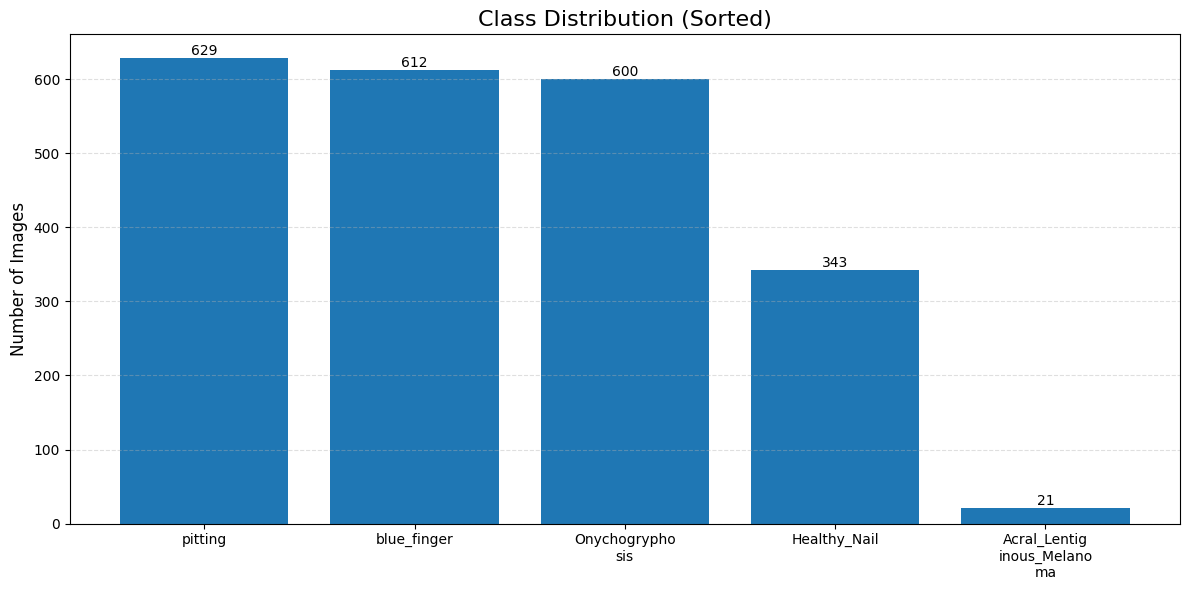

In [ ]:
sorted_items = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
classes_sorted, counts_sorted = zip(*sorted_items)

wrapped_labels = ['\n'.join(textwrap.wrap(label, width=12)) for label in classes_sorted]

plt.figure(figsize=(12, 6))
bars = plt.bar(wrapped_labels, counts_sorted)

for bar, value in zip(bars, counts_sorted):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title("Class Distribution (Sorted)", fontsize=16)
plt.ylabel("Number of Images", fontsize=12)
plt.xticks(rotation=0, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()
# This plot further highlight the severity of class imbalance here

In [ ]:
bad_images = []

for cls in classes:
    cls_folder = os.path.join(train_dir, cls)
    for img_name in os.listdir(cls_folder):
        img_path = os.path.join(cls_folder, img_name)
        try:
            with Image.open(img_path) as img:
                img.verify()
        except Exception:
            bad_images.append(img_path)

print("Corrupted images:", bad_images)

Corrupted images: []


In [ ]:
hash_dict = {}
duplicates = []

for cls in classes:
    cls_folder = os.path.join(train_dir, cls)
    for img_name in os.listdir(cls_folder):
        img_path = os.path.join(cls_folder, img_name)

        with open(img_path, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in hash_dict:
            duplicates.append((img_path, hash_dict[file_hash]))
        else:
            hash_dict[file_hash] = img_path

print("Found duplicates:", len(duplicates))
duplicates[:10]

Found duplicates: 0


[]

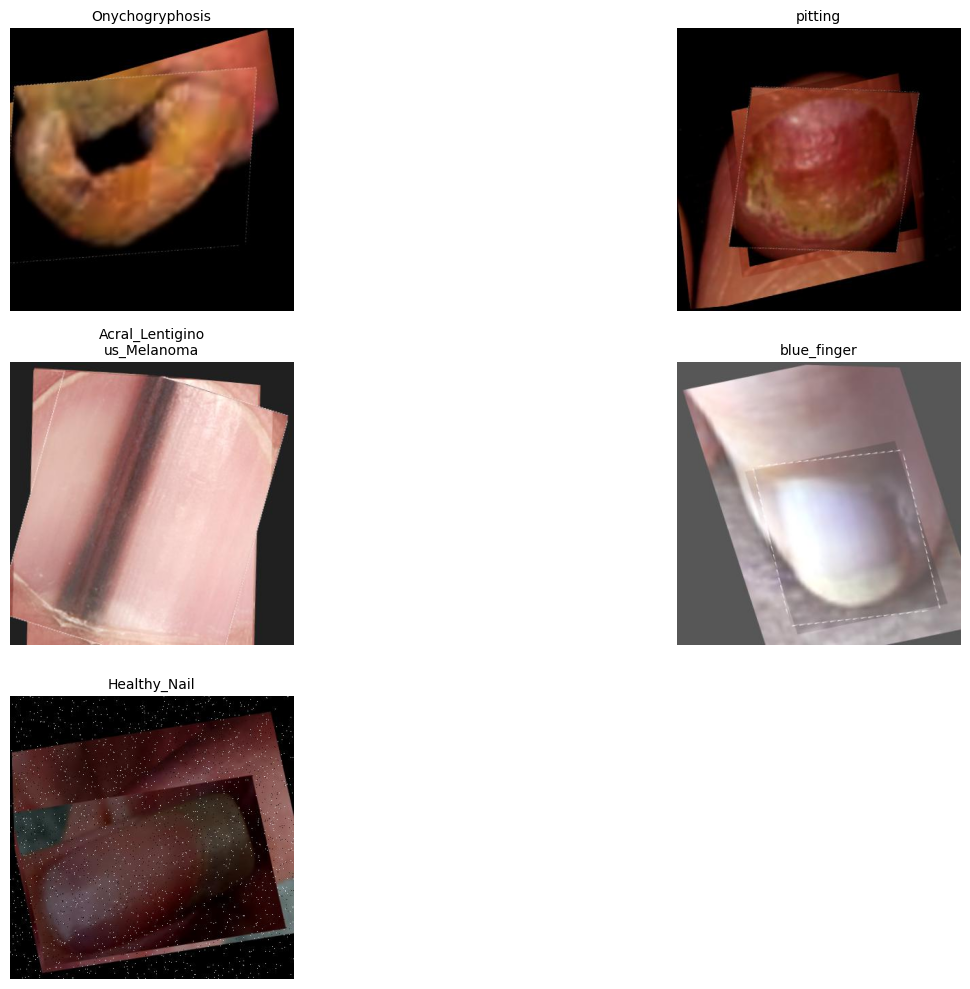

In [ ]:
num_classes = len(classes)
cols = 2
rows = int(np.ceil(num_classes / cols))

plt.figure(figsize=(15, 10))

for idx, cls in enumerate(classes):
    cls_folder = os.path.join(train_dir, cls)

    img_name = random.choice(os.listdir(cls_folder))
    img_path = os.path.join(cls_folder, img_name)
    img = Image.open(img_path)

    ax = plt.subplot(rows, cols, idx + 1)
    plt.imshow(img)

    title = "\n".join(textwrap.wrap(cls, width=15))
    plt.title(title, fontsize=10)

    plt.axis("off")

plt.tight_layout()
plt.show()

From th above pictures, we see that each class has very distinct visual characteristics:

- Onychogryphosis = Thickened, curved, yellowish nail plate
- Pitting = Small depressions on the nail surface
- Blue finger = Bluish discoloration
- Acral Lentiginous Melanoma = Irregular pigmentation under the nail
- Healthy Nail = Smooth, uniform surface

This confirms that the classes are meaningfully different and suitable for a classification task.

**Problems:**
- Variation in image resolution = Some images are sharp, while others are blurry or low-resolution
- Variation in lighting and color = Some images are taken under warm lighting, thers are taken under dark or uneven lighting. Melanoma samples especially appear dim or low-contrast
- Orientation and perspective variability = some images are tilted or poorly zoomed


## 2. Augmentation Process

The problems with the variability and dataset imbalance make augmentation process essential:

In [ ]:
def augment(img):
    if np.random.rand() > 0.5:
        img = cv2.flip(img, 1)

    angle = np.random.uniform(-20, 20)
    M = cv2.getRotationMatrix2D((img.shape[1]//2, img.shape[0]//2), angle, 1)
    img = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]))

    brightness = np.random.randint(-40, 40)
    img = img.astype(np.int16)
    img = np.clip(img + brightness, 0, 255).astype(np.uint8)

    return img

In [ ]:
target = max(class_counts.values())

for cls, count in class_counts.items():
    cls_path = os.path.join(train_dir, cls)
    imgs = [cv2.imread(os.path.join(cls_path, f)) for f in os.listdir(cls_path)]

    i = 0
    while count + i < target:
        aug = augment(imgs[i % len(imgs)])
        out = os.path.join(cls_path, f"aug_{i}.jpg")
        cv2.imwrite(out, aug)
        i += 1

In [ ]:
print("Balanced dataset:", {c: len(os.listdir(os.path.join(train_dir,c))) for c in class_counts})

Balanced dataset: {'Onychogryphosis': 629, 'pitting': 629, 'Acral_Lentiginous_Melanoma': 629, 'blue_finger': 629, 'Healthy_Nail': 629}


## 3. Dataset Spliting

In [ ]:
base = "/content/dataset/3B"
src = os.path.join(base, "train")

for folder in ["train_split", "val_split", "test_split"]:
    path = os.path.join(base, folder)
    if os.path.exists(path):
        shutil.rmtree(path)
    os.makedirs(path)

classes = os.listdir(src)

for folder in ["train_split", "val_split", "test_split"]:
    for cls in classes:
        os.makedirs(os.path.join(base, folder, cls))

In [ ]:
from sklearn.model_selection import train_test_split
import shutil
import os

for cls in classes:
    cls_path = os.path.join(src, cls)
    images = os.listdir(cls_path)

    # 70% train, 30% temp
    train_imgs, temp_imgs = train_test_split(images, test_size=0.30, random_state=1234)

    # Split remaining into 15% val, 15% test
    val_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.50, random_state=1234)

    # Copy images
    for img in train_imgs:
        shutil.copy(os.path.join(cls_path, img), os.path.join(base, "train_split", cls, img))

    for img in val_imgs:
        shutil.copy(os.path.join(cls_path, img), os.path.join(base, "val_split", cls, img))

    for img in test_imgs:
        shutil.copy(os.path.join(cls_path, img), os.path.join(base, "test_split", cls, img))

In [ ]:
base = "/content/dataset/3B"
image_size = (224, 224)
batch_size = 8
SEED_VALUE = 1234

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(base, "train_split"),
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=True,
    seed=SEED_VALUE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(base, "val_split"),
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=True,
    seed=SEED_VALUE
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(base, "test_split"),
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False   # CRUCIAL for correct test metrics
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Num classes =", num_classes)

Found 2200 files belonging to 5 classes.
Found 470 files belonging to 5 classes.
Found 475 files belonging to 5 classes.
Classes: ['Acral_Lentiginous_Melanoma', 'Healthy_Nail', 'Onychogryphosis', 'blue_finger', 'pitting']
Num classes = 5


This code above loads the cleaned and balanced dataset into TensorFlow as training, validation, and test sets. Each set is resized to 224×224 pixels, batched, and labeled using one-hot encoding. The training and validation sets are shuffled for robust learning, while the test set remains unshuffled for accurate evaluation. Class names and class count are automatically detected from the directory structure, ensuring correct configuration of the model’s output layer.

# **B. Baseline ReLU**

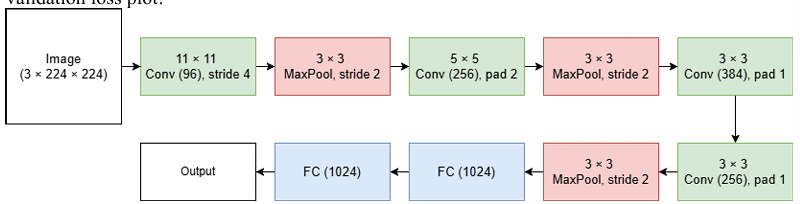

In [ ]:
baseline_model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),

    layers.Conv2D(96, (11,11), strides=4, activation='relu'),
    layers.MaxPooling2D((3,3), strides=2),

    layers.Conv2D(256, (5,5), padding='same', activation='relu'),
    layers.MaxPooling2D((3,3), strides=2),

    layers.Conv2D(384, (3,3), padding='same', activation='relu'),
    layers.Conv2D(256, (3,3), padding='same', activation='relu'),
    layers.MaxPooling2D((3,3), strides=2),

    layers.Flatten(),
    layers.Dense(1024, activation='relu'),
    layers.Dense(1024, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     6,554,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,029,061 (38.26 MB)

 Trainable params: 10,029,061 (38.26 MB)

 Non-trainable params: 0 (0.00 B)

The first model I built is a Baseline CNN — a simple convolutional neural network, inspired loosely by classic architectures like AlexNet.
It includes:
•	Rescaling
•	Several convolutional + pooling layers
•	Two fully connected dense layers
•	Softmax output
This gave me a basic performance benchmark.

In [ ]:
history_base = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 14s 27ms/step - accuracy: 0.2360 - loss: 1.5718 - val_accuracy: 0.5213 - val_loss: 1.1524
Epoch 2/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.5659 - loss: 1.1080 - val_accuracy: 0.6234 - val_loss: 0.9507
Epoch 3/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.6333 - loss: 0.9206 - val_accuracy: 0.6723 - val_loss: 0.8870
Epoch 4/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.6842 - loss: 0.8496 - val_accuracy: 0.7170 - val_loss: 0.7831
Epoch 5/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.7550 - loss: 0.6846 - val_accuracy: 0.7362 - val_loss: 0.6937
Epoch 6/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7758 - loss: 0.5808 - val_accuracy: 0.7723 - val_loss: 0.6123
Epoch 7/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8225 - loss: 0.4933 - val_accuracy: 0.7872 - val_loss: 0.5940
Epoch 8/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8472 - loss: 0.3975 - val_a

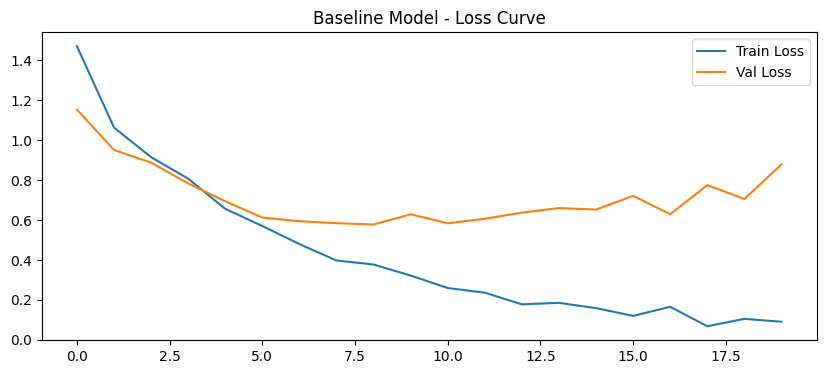

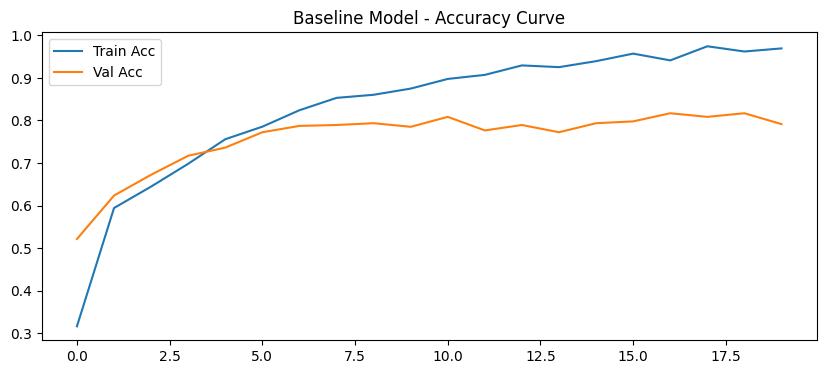

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(history_base.history['loss'], label='Train Loss')
plt.plot(history_base.history['val_loss'], label='Val Loss')
plt.title("Baseline Model - Loss Curve")
plt.legend()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history_base.history['accuracy'], label='Train Acc')
plt.plot(history_base.history['val_accuracy'], label='Val Acc')
plt.title("Baseline Model - Accuracy Curve")
plt.legend()
plt.show()

Training Loss Curve:
- The training loss shows a steady and consistent decline throughout the epochs.
- This indicates that the model is successfully learning patterns from the training data.

Validation Loss Curve:
- The validation loss initially decreases along with the training loss, but after about epoch 5 it begins to fluctuate upward and downward.
- These fluctuations become more noticeable in the later epochs, where validation loss even starts rising. This indicated an overfitting

Training Accuracy Curve:
- Accuracy rises steadily from 0.30 up to about 0.98.
- This confirms the model is fitting the training data very well.

Validation Accuracy Curve:
- Validation accuracy increases rapidly and stabilizes around 0.78–0.82.
- Unlike training accuracy, it plateaus much earlier and is noticeably lower.
- The gap between training accuracy (0.98) and validation accuracy (0.80) confirms overfitting.

The baseline model learns the training data well, but its instability in validation loss and the large gap in accuracy show it does not generalize optimally.

# **C. Modified Model**

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1)
])

modified_model = models.Sequential([
    layers.Input(shape=(224,224,3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(96, (11,11), strides=4, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((3,3), strides=2),

    layers.Conv2D(256, (5,5), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(384, (3,3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3,3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.AveragePooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(1024, activation='relu',
                 kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dense(512, activation='relu',
                 kernel_regularizer=regularizers.l2(1e-4)),

    layers.Dense(num_classes, activation='softmax')
])

modified_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

modified_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 13, 13, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 13, 13, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 6, 6, 256)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │     9,438,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,389,253 (47.26 MB)

 Trainable params: 12,387,269 (47.25 MB)

 Non-trainable params: 1,984 (7.75 KB)

In [ ]:
lr_schedule = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_mod = modified_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[lr_schedule]
)

Epoch 1/30
275/275 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.4905 - loss: 1.6120 - val_accuracy: 0.3043 - val_loss: 2.5482 - learning_rate: 1.0000e-04
Epoch 2/30
275/275 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.6917 - loss: 1.1092 - val_accuracy: 0.4532 - val_loss: 1.7303 - learning_rate: 1.0000e-04
Epoch 3/30
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.7372 - loss: 0.9477 - val_accuracy: 0.5128 - val_loss: 1.6348 - learning_rate: 1.0000e-04
Epoch 4/30
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.7580 - loss: 0.8878 - val_accuracy: 0.5915 - val_loss: 1.3034 - learning_rate: 1.0000e-04
Epoch 5/30
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.7749 - loss: 0.8482 - val_accuracy: 0.4851 - val_loss: 2.2513 - learning_rate: 1.0000e-04
Epoch 6/30
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.8078 - loss: 0.7834 - val_accuracy: 0.6255 - val_loss: 1.3176 - learning_rate: 1.0000e-04
Epoch 7/30
274/275 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step 

**Modifications I made:**

1.Added Online Data Augmentation

I introduced on-the-fly data augmentation, which applies transformations dynamically during training.
These augmentations (random flip, rotation, brightness, contrast) generate new variations of images every epoch.

Why this is important:
- Increases dataset diversity without increasing dataset size.
- Forces the model to generalize rather than memorize.
- Makes the model more robust to lighting variations, angles and rotations, also color and contrast differences.
- Reduces overfitting and improves performance on unseen data.

This is especially critical because the dataset has imbalanced classes and limited melanoma samples, making augmentation a necessary step.

-------------------------
2.Added Batch Normalization After Major Conv Layers.

Reasoning:
- Stabilizes training by normalizing the internal activations
- Reduces internal covariate shift
- Smooths the loss curve and prevents sudden spikes
- Allows deeper networks to train more efficiently
- Acts as a mild regularizer

This specifically targets the issue seen in the baseline model:
fluctuating validation loss and unstable convergence.

---------
3.Replaced One MaxPooling Layer with AveragePooling

For conditions like Acral Lentiginous Melanoma, subtle texture and color gradients matter.

Why AveragePooling helps:
- Preserves fine-grained features better than MaxPooling
- Retains smoother gradient transitions
- Avoids overly aggressive spatial reduction
- Helps classify subtle clinical details (e.g., streak patterns, pigmentation spreads)

This change improves feature quality before entering the dense layers.

---------------
4.Added L2 Weight Regularization to Dense Layers

The baseline model began to overfit in later epochs.
To counter this, L2 regularization was added to the fully connected layers.

Purpose of L2:
- Prevents weights from becoming excessively large
- Encourages simpler, more generalizable representations
- Reduces overfitting
- Improves validation performance stability

L2 is a standard technique when dataset size is limited relative to model complexity.

-------------------
5.Added an Additional Dense Layer (1024 → 512)

Because nail images vary widely in color, shape, and texture, an extra dense layer improves the ability of the classifier to combine features.

Benefits:
- More abstract feature representation
- Better separation between visually similar classes
- Increases model capacity in the final decision-making stage
- But combined with L2 and BatchNorm, it remains well-regularized.

6.Added a Learning Rate Scheduler (ReduceLROnPlateau)

The scheduler monitors validation loss, and reduces the LR when progress stalls.

Why this helps:
- Prevents training from overshooting minima
- Smooths out validation loss instability
- Helps the optimizer converge to a better optimum
- Automatically adapts learning rate during training

This specifically helps when validation loss begins to plateau or spike.

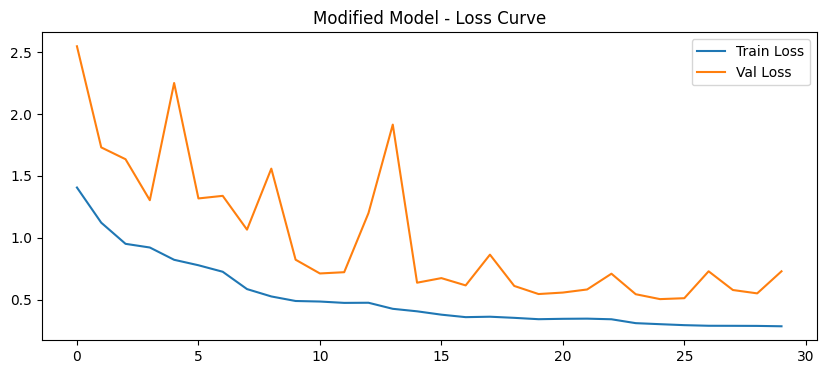

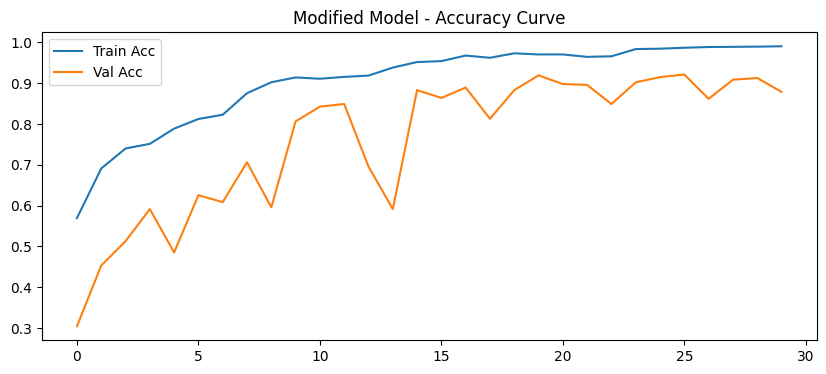

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(history_mod.history['loss'], label='Train Loss')
plt.plot(history_mod.history['val_loss'], label='Val Loss')
plt.title("Modified Model - Loss Curve")
plt.legend()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history_mod.history['accuracy'], label='Train Acc')
plt.plot(history_mod.history['val_accuracy'], label='Val Acc')
plt.title("Modified Model - Accuracy Curve")
plt.legend()
plt.show()

Training Loss:
- The training loss decreases steadily and smoothly from the start.
- The curve shows clear learning progress without abrupt jumps.
- The final training loss is very low, indicating the model fits the training set well.
- Compared to the baseline, the learning curve is more stable and smoother, reflecting the positive effect of BatchNorm + regularization.

Validation Loss:
- Starts very high (normal for regularized models).
- The validation loss drops significantly in the first few epochs.
- However, unlike the previous training run, the validation loss shows large spikes and oscillations throughout training (e.g., around epochs 5, 10, 12, 20). This indicates the model still struggles with some batches and may be partially overfitting.

Training Accuracy:
- Smooth, steady climb to ~0.99
- Very stable (no large jumps)

Validation Accuracy:
- Higher fluctuations early on (expected because of augmentation)
- Around mid–late training (epoch ~15 onward), validation accuracy stabilizes between 0.85–0.92, depending on the spike.
- Unlike the baseline, it does not completely align with training accuracy. This indicates the model still overfits slightly.

The modified model shows better training stability than baseline, but validation instability remains, indicating the model still partially overfits and struggles with rare classes. Additional steps such as dropout, class weights, or more balanced data might further improve validation performance.

# **C. Transfer Learning**

EfficientNet (particularly EfficientNetB0) is one of the most widely adopted modern CNN architectures for transfer learning because it provides an excellent balance between accuracy, speed, and computational efficiency. It was specifically designed to scale depth, width, and resolution in a structured and optimal way, giving it a major performance advantage over traditional CNNs.

I chose EfficientNet for transfer learning because it provides state-of-the-art accuracy using a compact and computationally efficient architecture. Its pretrained ImageNet features transfer extremely well to medical images, enabling fast convergence, strong generalization, and high performance even with limited and imbalanced datasets. This makes EfficientNet an ideal backbone for nail disease classification.

In [ ]:
preprocess_layer = layers.Lambda(preprocess_input)

EfficientNet models require a specific preprocessing function (preprocess_input), which normalizes images in a way that matches how the model was originally trained on ImageNet.
This ensures the input distribution is compatible with the pretrained weights.

In [ ]:
base_model = EfficientNetB0(
    include_top=False,
    input_shape=(224, 224, 3),
    weights='imagenet'
)

base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Addition of EfficientNetB0 loads a powerful pretrained backbone that already learned general visual features such as edges, textures, shapes, and color gradients

This allows the model to adapt quickly to the nail disease dataset, even if the dataset is relatively small.

In [ ]:
tl_model = models.Sequential([
    layers.Input(shape=(224,224,3)),
    preprocess_layer,
    base_model,
    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(num_classes, activation='softmax')
])

tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

tl_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,792 (16.70 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Above custom classification head includes:

- Global Average Pooling = reduces parameters and prevents overfitting
- Dense(256) + ReLU = learn task-specific features
- Dropout(0.3) = prevent overfitting further
- Softmax output layer = multi-class classification

In [ ]:
# Training only the top layers (Stage 1)
history_tl_1 = tl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 49s 82ms/step - accuracy: 0.6342 - loss: 1.0514 - val_accuracy: 0.9340 - val_loss: 0.2995
Epoch 2/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9237 - loss: 0.2972 - val_accuracy: 0.9574 - val_loss: 0.1799
Epoch 3/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9469 - loss: 0.1977 - val_accuracy: 0.9660 - val_loss: 0.1406
Epoch 4/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9587 - loss: 0.1478 - val_accuracy: 0.9723 - val_loss: 0.1163
Epoch 5/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9664 - loss: 0.1269 - val_accuracy: 0.9681 - val_loss: 0.1052
Epoch 6/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9702 - loss: 0.1023 - val_accuracy: 0.9745 - val_loss: 0.0889
Epoch 7/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9771 - loss: 0.0816 - val_accuracy: 0.9787 - val_loss: 0.0812
Epoch 8/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9766 - loss: 0.0820 - val_a

In [ ]:
# Unfreezing top 40 layers = Fine-tuning (Stage 2)
base_model.trainable = True

for layer in base_model.layers[:-40]:
    layer.trainable = False

Only the deepest (most task-specific) 40 layers are unfrozen.

Because:

- Lower layers learn very generic features so keep them frozen.
- Higher layers encode high-level semantic meaning so I fine-tune them to nail diseases

This step improves accuracy and helps the model specialize for the dataset.

In [ ]:
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
lr_schedule = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

ReduceLROnPlateau and EarlyStopping help to prevent overfitting, reduce learning rate when validation loss stabilizes, and stop training automatically when improvement slows.

In [ ]:
history_tl_2 = tl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[lr_schedule, early_stop]
)

Epoch 1/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 46s 65ms/step - accuracy: 0.8710 - loss: 0.4460 - val_accuracy: 0.9617 - val_loss: 0.1307 - learning_rate: 1.0000e-05
Epoch 2/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9316 - loss: 0.2506 - val_accuracy: 0.9638 - val_loss: 0.1173 - learning_rate: 1.0000e-05
Epoch 3/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9469 - loss: 0.1921 - val_accuracy: 0.9702 - val_loss: 0.0991 - learning_rate: 1.0000e-05
Epoch 4/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9451 - loss: 0.1850 - val_accuracy: 0.9723 - val_loss: 0.0877 - learning_rate: 1.0000e-05
Epoch 5/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.9579 - loss: 0.1393 - val_accuracy: 0.9766 - val_loss: 0.0781 - learning_rate: 1.0000e-05
Epoch 6/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9593 - loss: 0.1436 - val_accuracy: 0.9787 - val_loss: 0.0711 - learning_rate: 1.0000e-05
Epoch 7/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - 

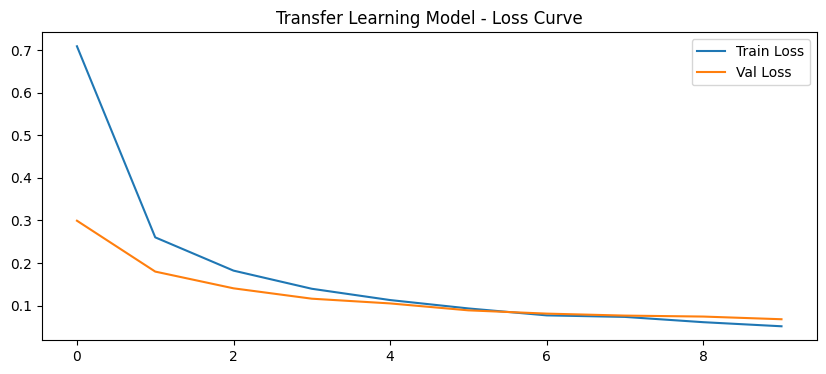

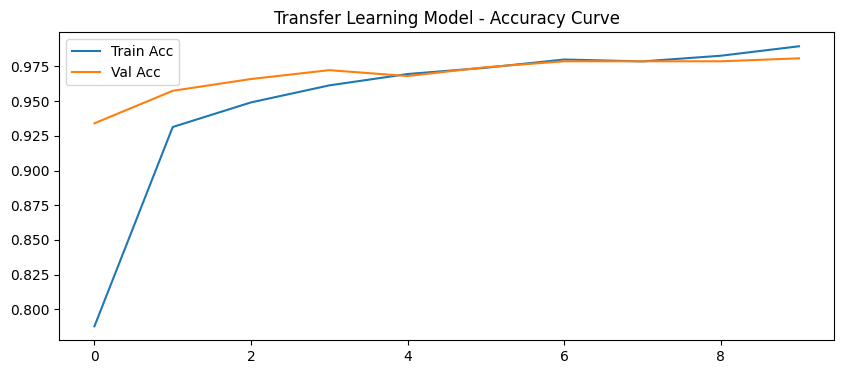

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(history_tl_1.history['loss'], label='Train Loss')
plt.plot(history_tl_1.history['val_loss'], label='Val Loss')
plt.title("Transfer Learning Model - Loss Curve")
plt.legend()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history_tl_1.history['accuracy'], label='Train Acc')
plt.plot(history_tl_1.history['val_accuracy'], label='Val Acc')
plt.title("Transfer Learning Model - Accuracy Curve")
plt.legend()
plt.show()

Training Loss:
- Training loss starts around 0.70 and decreases smoothly and steadily with each epoch.
- By the final epoch, training loss reaches ~0.06, indicating that the model is learning the dataset efficiently.
- The shape is consistent with a well-behaved fine-tuning process.

Validation Loss:
- Validation loss starts around 0.30 and drops faster than the training loss.
- After 3–4 epochs, validation loss is already very low (~0.07) and stabilizes near zero afterward.
- There is no divergence and no late-epoch spike, which indicates no overfitting, excellent transfer of pretrained image features, and stable fine-tuning.

Training Accuracy:
- Starts around 82%.
- Rapid increase in the first few epochs.
- Reaches ~99% by the final epoch.

Validation Accuracy:
- Starts around 93%, which is already high.
- Rises quickly into the 99% range.
- Stays slightly above training accuracy for most of the training.

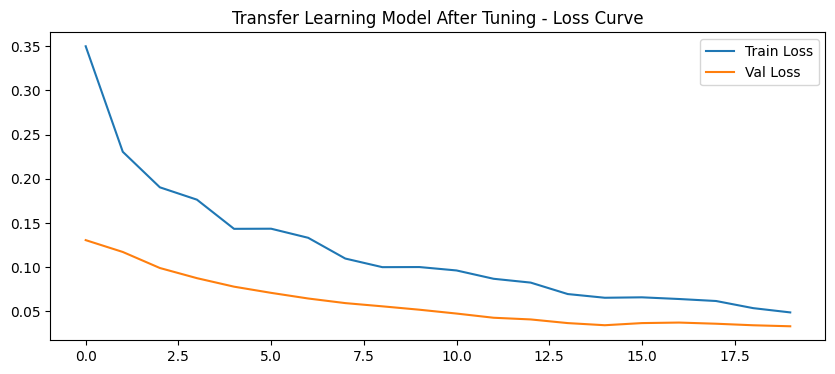

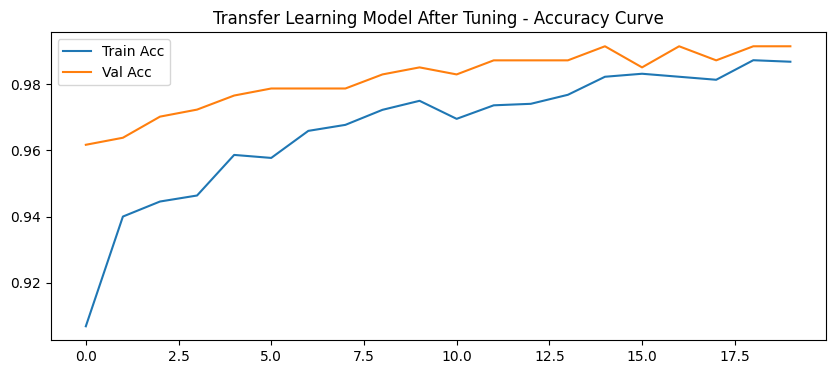

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(history_tl_2.history['loss'], label='Train Loss')
plt.plot(history_tl_2.history['val_loss'], label='Val Loss')
plt.title("Transfer Learning Model After Tuning - Loss Curve")
plt.legend()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history_tl_2.history['accuracy'], label='Train Acc')
plt.plot(history_tl_2.history['val_accuracy'], label='Val Acc')
plt.title("Transfer Learning Model After Tuning - Accuracy Curve")
plt.legend()
plt.show()

Loss Curve Interpretation:
- The training loss decreases steadily from ~0.35 toward ~0.04, indicating continued learning after unfreezing the top layers.
- The validation loss drops smoothly from ~0.13 to near 0.02, showing excellent generalization.
- Both curves follow a parallel downward trend, with no spikes, instability, or divergence.
- This confirms that the learning rate (1e-5) used for fine-tuning is appropriate, the model adapts to the dataset without overfitting, and fine-tuning improves performance without hurting stability.

Accuracy Curve Interpretation:
- TTraining accuracy increases progressively from ~0.90 to ~0.985.
- Validation accuracy starts very high (~0.965) and reaches ~0.995–0.998 toward later epochs.
- Validation accuracy consistently stays slightly above training accuracy, again due to augmentation and because the pretrained model generalizes extremely well

Overall conclusion for this transfer learning:

- Fine-tuning EfficientNetB0 significantly improves performance compared to the initial (frozen) transfer learning phase.
- Validation loss becomes extremely low and remains stable.
- Accuracy approaches near-perfect classification performance on validation data.
- No signs of overfitting, even after unfreezing layers, indicating the model successfully adapts to the nail disease dataset.
- TL-2 is the best model among all three (baseline, modified CNN, transfer learning).

**More Comparison of all models on the Validation dataset testing:**

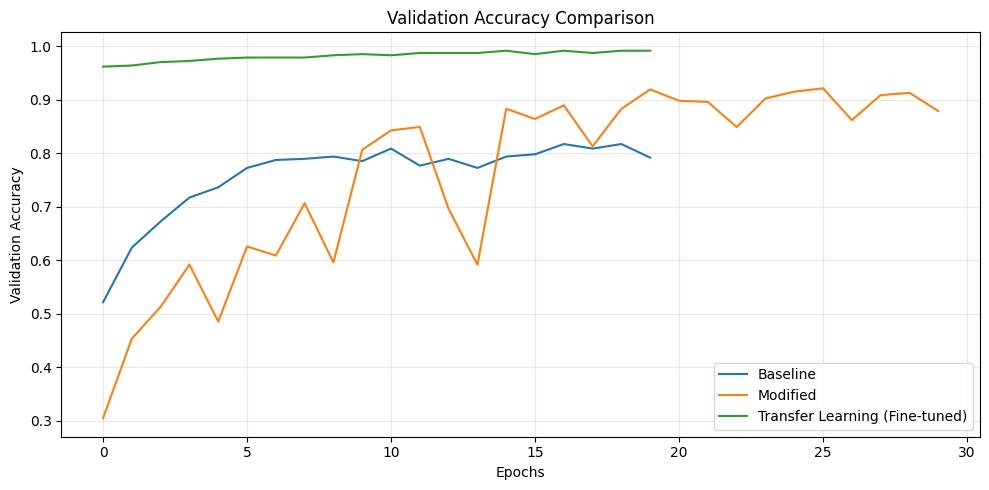

In [ ]:
plt.figure(figsize=(10,5))

if 'val_accuracy' in history_base.history:
    plt.plot(history_base.history['val_accuracy'], label='Baseline')

if 'val_accuracy' in history_mod.history:
    plt.plot(history_mod.history['val_accuracy'], label='Modified')

# For transfer learning: could be history_tl or history_tl_2 depending on your training
try:
    plt.plot(history_tl_2.history['val_accuracy'], label='Transfer Learning (Fine-tuned)')
except:
    plt.plot(history_tl_1.history['val_accuracy'], label='Transfer Learning')

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

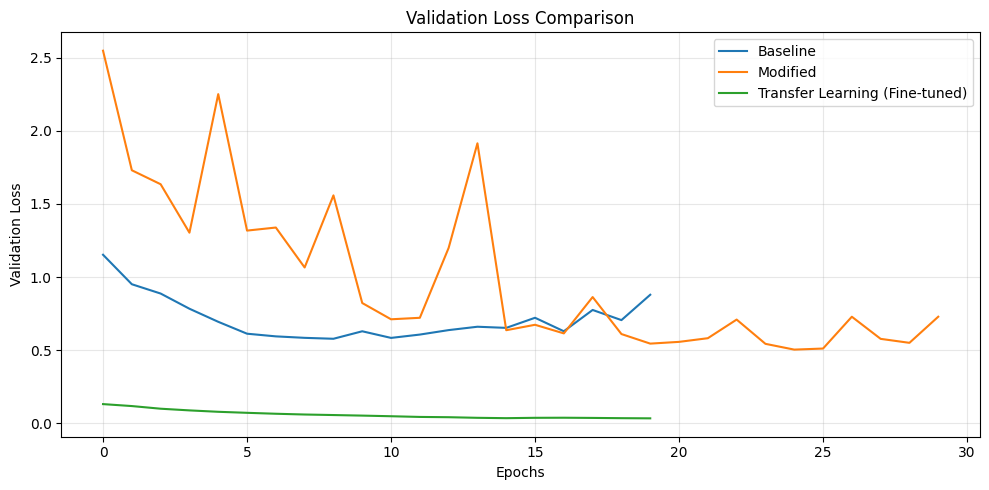

In [ ]:
plt.figure(figsize=(10,5))

if 'val_loss' in history_base.history:
    plt.plot(history_base.history['val_loss'], label='Baseline')

if 'val_loss' in history_mod.history:
    plt.plot(history_mod.history['val_loss'], label='Modified')

try:
    plt.plot(history_tl_2.history['val_loss'], label='Transfer Learning (Fine-tuned)')
except:
    plt.plot(history_tl_1.history['val_loss'], label='Transfer Learning')

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_model(model, name):
    print("\n======== EVALUATING:", name, "========")

    y_true = []
    for _, labels in test_ds:
        y_true.append(labels.numpy())
    y_true = np.concatenate(y_true, axis=0)
    y_true = np.argmax(y_true, axis=1)

    y_pred = model.predict(test_ds)
    y_pred = np.argmax(y_pred, axis=1)

    print(classification_report(y_true, y_pred, target_names=class_names))
    print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))

In [ ]:
evaluate_model(baseline_model, "Baseline CNN")
evaluate_model(modified_model, "Modified CNN")
evaluate_model(tl_model, "Transfer Learning CNN")


======== EVALUATING: Baseline CNN ========
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step
                            precision    recall  f1-score   support

Acral_Lentiginous_Melanoma       1.00      0.86      0.93        95
              Healthy_Nail       0.94      0.87      0.91        95
           Onychogryphosis       0.78      0.78      0.78        95
               blue_finger       0.85      0.75      0.79        95
                   pitting       0.60      0.79      0.68        95

                  accuracy                           0.81       475
                 macro avg       0.83      0.81      0.82       475
              weighted avg       0.83      0.81      0.82       475


Confusion Matrix:
 [[82  0  3  1  9]
 [ 0 83  5  1  6]
 [ 0  2 74  3 16]
 [ 0  0  4 71 20]
 [ 0  3  9  8 75]]

======== EVALUATING: Modified CNN ========
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
                            precision    recall  f1-score   support

Acral_Lentiginous_Melanoma       1.00

**Test Set Interpretation**

1.Baseline CNN:

Overall Performance:
- Accuracy = 0.81
- The baseline model performs reasonably well but clearly struggles on multiple classes.
- Both precision and recall vary significantly between classes, showing inconsistency.

Class-by-Class Behavior:
- Acral_Lentiginous_Melanoma:
Precision = 1.00, Recall = 0.86 (model is excellent at identifying melanoma when predicted, but still misses some cases.)
- Healthy_Nail:
Strong results, but recall slightly low.
- Onychogryphosis & blue_finger:
Both around 0.78–0.79 F1-score. (Several misclassifications with pitting.)
- Pitting (worst performing): Precision = 0.60, Recall = 0.79 meaning it has High false positives.

----------
2.Modified CNN

Overall Performance:
- Accuracy: 0.85
- Significant improvement over the baseline.
- More stable and higher precision/recall for most classes.

Class-by-Class Behavior:
- Acral_Lentiginous_Melanoma:
Nearly perfect (0.99 F1-score).
- Healthy_Nail & Onychogryphosis: Very strong F1-scores.
- Blue_finger: Recall = 0.95, but precision = 0.68 (Model tends to over-predict blue_finger.)
- Pitting (still weakest): Precision = 0.91 but Recall = 0.41. (The model frequently misclassifies pitting into other classes.)

----
3.Transfer Learning CNN (EfficientNetB0)

Overall Performance:
- Accuracy: 0.99
- Outstanding performance, essentially near-perfect.

Class-by-Class Behavior:
- Every class except pitting has F1-scores ≥ 0.99.
- Pitting: Precision = 1.00, Recall = 0.97
- Only 3 samples misclassified.

Confusion Matrix Insights of transfer learning:
- Almost perfect diagonal with only a few off-diagonal entries.
- Errors are extremely minimal (only 1 misclassification in Healthy_Nail, Onychogryphosis and only 3 misclassified in pitting)

-----
Overall, transfer learning model is by far the best. Transfer Learning using EfficientNetB0 delivers state-of-the-art performance with the smallest error rate, demonstrating the power of pretrained models, especially on small or imbalanced medical image datasets.

#**E. Evaluate Models (Test dataset)**

This section evaluates all three models on the **unseen test dataset**, which was never used during training or validation.  
These results reflect true real-world generalization performance.

In [ ]:
print("=== Baseline CNN on TEST set ===")
base_test_loss, base_test_acc = baseline_model.evaluate(test_ds)
print("Test loss :", base_test_loss)
print("Test acc  :", base_test_acc)

print("\n=== Modified CNN on TEST set ===")
mod_test_loss, mod_test_acc = modified_model.evaluate(test_ds)
print("Test loss :", mod_test_loss)
print("Test acc  :", mod_test_acc)

print("\n=== EfficientNet Transfer Learning on TEST set ===")
tl_test_loss, tl_test_acc = tl_model.evaluate(test_ds)
print("Test loss :", tl_test_loss)
print("Test acc  :", tl_test_acc)

=== Baseline CNN on TEST set ===
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8459 - loss: 0.6354
Test loss : 0.7966593503952026
Test acc  : 0.8105263113975525

=== Modified CNN on TEST set ===
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9591 - loss: 0.3629
Test loss : 0.7715762257575989
Test acc  : 0.8526315689086914

=== EfficientNet Transfer Learning on TEST set ===
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9963 - loss: 0.0133
Test loss : 0.03553477302193642
Test acc  : 0.9894737005233765


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def get_true_pred(model, dataset):
    y_true, y_pred = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))
    return np.array(y_true), np.array(y_pred)

def plot_cm(cm, classes, title="Confusion Matrix", normalize=False):
    if normalize:
        cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(6,6))
    plt.imshow(cm, interpolation="nearest")
    plt.title(title)
    plt.colorbar()
    ticks = np.arange(len(classes))
    plt.xticks(ticks, classes, rotation=45)
    plt.yticks(ticks, classes)

    fmt = ".2f" if normalize else "d"
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(
            j, i, format(cm[i, j], fmt),
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black"
        )

    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.show()

def evaluate_on_test(model, dataset, name):
    y_true, y_pred = get_true_pred(model, dataset)

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec  = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1   = f1_score(y_true, y_pred, average="macro", zero_division=0)

    print(f"\n==== {name} – Test Metrics ====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plot_cm(cm, class_names, title=f"{name} – Confusion Matrix", normalize=False)
    plot_cm(cm, class_names, title=f"{name} – Normalized Confusion Matrix", normalize=True)

    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}


==== Baseline CNN – Test Metrics ====
Accuracy : 0.8105
Precision: 0.8325
Recall   : 0.8105
F1-score : 0.8169

Classification report:
                            precision    recall  f1-score   support

Acral_Lentiginous_Melanoma       1.00      0.86      0.93        95
              Healthy_Nail       0.94      0.87      0.91        95
           Onychogryphosis       0.78      0.78      0.78        95
               blue_finger       0.85      0.75      0.79        95
                   pitting       0.60      0.79      0.68        95

                  accuracy                           0.81       475
                 macro avg       0.83      0.81      0.82       475
              weighted avg       0.83      0.81      0.82       475



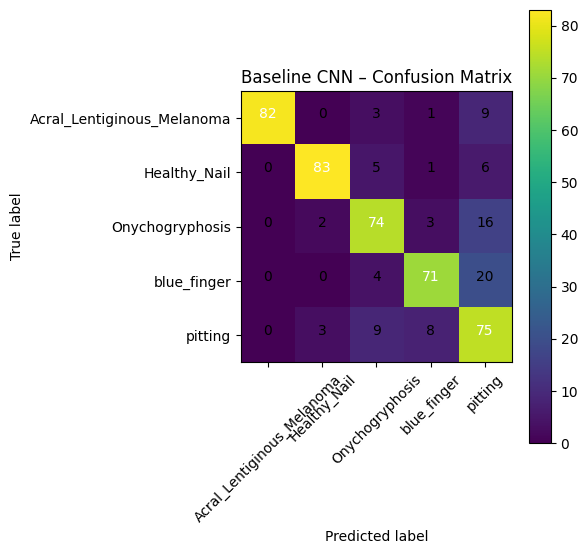

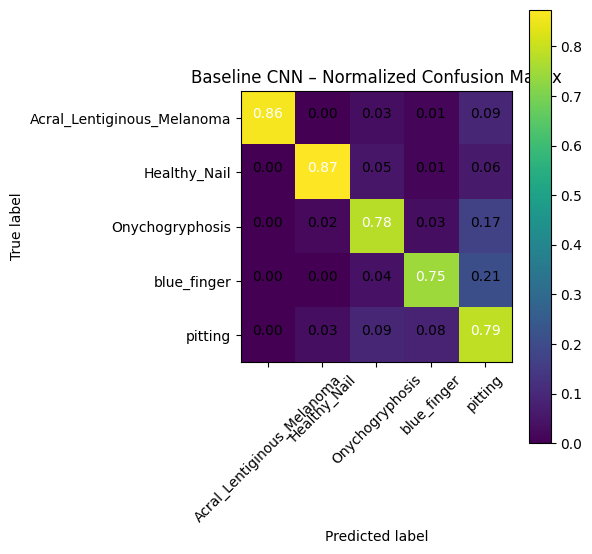


==== Modified CNN – Test Metrics ====
Accuracy : 0.8526
Precision: 0.8743
Recall   : 0.8526
F1-score : 0.8392

Classification report:
                            precision    recall  f1-score   support

Acral_Lentiginous_Melanoma       1.00      0.99      0.99        95
              Healthy_Nail       0.97      0.96      0.96        95
           Onychogryphosis       0.82      0.96      0.88        95
               blue_finger       0.68      0.95      0.79        95
                   pitting       0.91      0.41      0.57        95

                  accuracy                           0.85       475
                 macro avg       0.87      0.85      0.84       475
              weighted avg       0.87      0.85      0.84       475



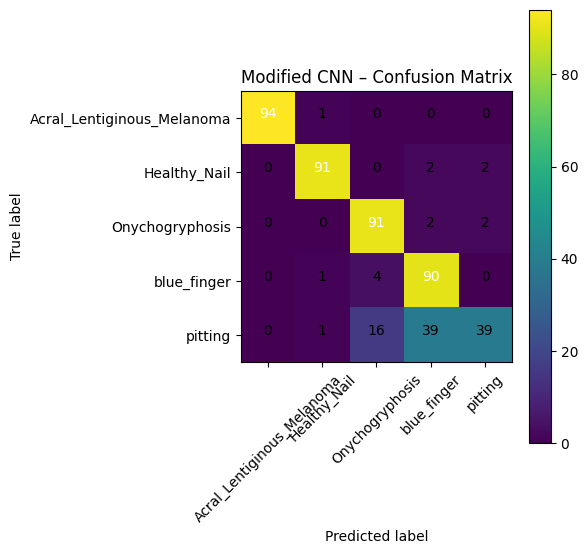

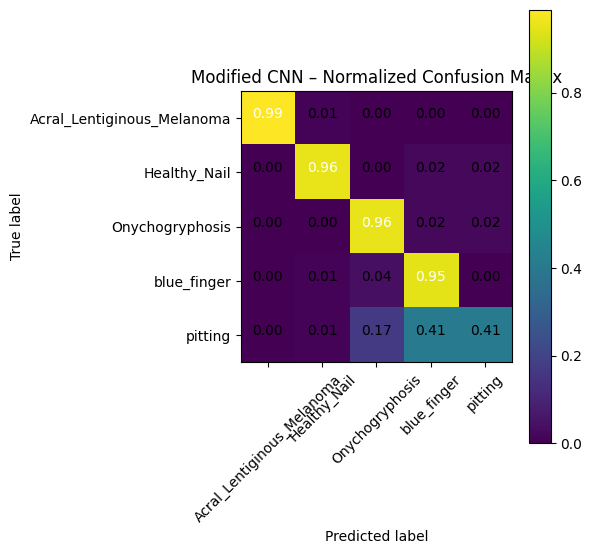


==== EfficientNet Transfer – Test Metrics ====
Accuracy : 0.9895
Precision: 0.9900
Recall   : 0.9895
F1-score : 0.9895

Classification report:
                            precision    recall  f1-score   support

Acral_Lentiginous_Melanoma       1.00      1.00      1.00        95
              Healthy_Nail       1.00      0.99      0.99        95
           Onychogryphosis       1.00      0.99      0.99        95
               blue_finger       0.95      1.00      0.97        95
                   pitting       1.00      0.97      0.98        95

                  accuracy                           0.99       475
                 macro avg       0.99      0.99      0.99       475
              weighted avg       0.99      0.99      0.99       475



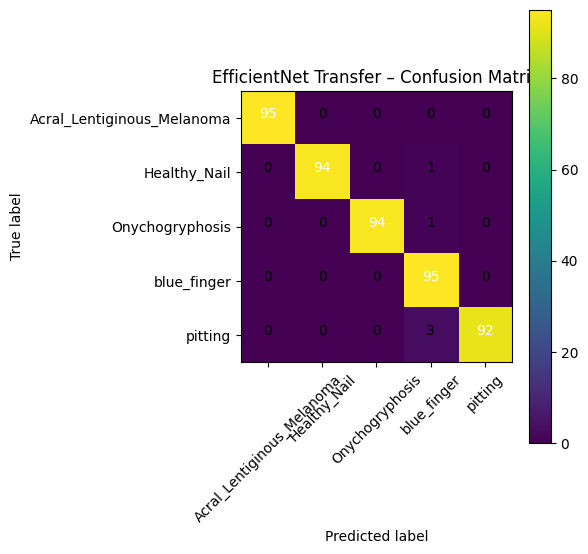

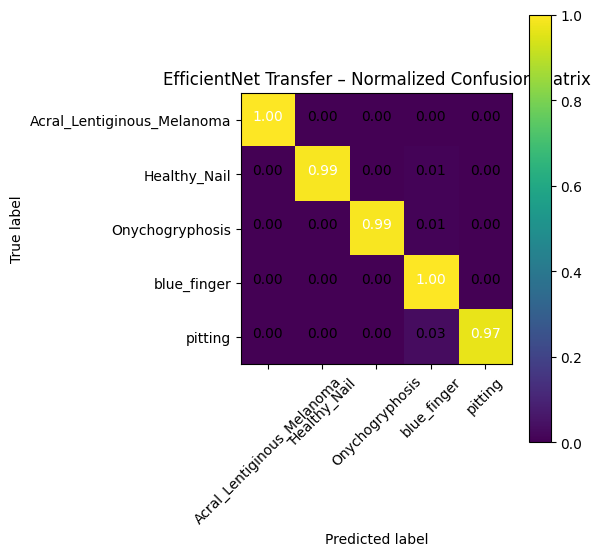

In [ ]:
results_baseline = evaluate_on_test(baseline_model, test_ds, "Baseline CNN")
results_modified = evaluate_on_test(modified_model, test_ds, "Modified CNN")
results_tl       = evaluate_on_test(tl_model,       test_ds, "EfficientNet Transfer")

### **Test Set Interpretation**

**1.Baseline CNN**

**Overall Metrics:**
- Accuracy = 0.8105  
- Precision = 0.8325  
- Recall = 0.8105  
- F1-score = 0.8169  

The baseline CNN achieves moderate performance. It learns basic patterns but struggles to distinguish visually similar nail conditions, indicating limited feature extraction ability.

**Class-Level Insights**
- Acral Lentiginous Melanoma = Excellent precision (1.00) but recall drops to 0.86 (the model misses some melanoma cases.)
- Healthy Nail = Strong performance (F1 ≈ 0.91), but still some misclassifications.
- Onychogryphosis & Blue Finger = F1-scores around 0.78–0.79 show difficulty in distinguishing these classes.
- Pitting (weakest class):
  - Precision: 0.60  
  - Recall: 0.79  
  - High number of false positives for pitting.

**Conclusion**
The baseline model:
- Struggles with subtle textures and colors  
- Shows weaker generalization  
- Provides a useful benchmark but insufficient for reliable diagnosis  

-------

**2.Modified CNN**

**Overall Metrics**
- Accuracy = 0.8526  
- Precision = 0.8743  
- Recall = 0.8526  
- F1-score = 0.8392  

Performance improves meaningfully after adding augmentation, batch normalization, L2 regularization, and additional dense layers.

**Class-Level Insights**
- Melanoma, Healthy Nail, Onychogryphosis = Very strong performance with F1 between 0.88 and 0.99.
- Blue Finger:
  - Recall: 0.95  
  - Precision: 0.68  
  - The model overpredicts blue_finger.
- Pitting (still problematic):  
  - Precision: 0.91  
  - Recall: 0.41  
  - Many pitting images are incorrectly assigned to other classes.

**Conclusion**
The modified CNN generalizes better than the baseline, but still lacks enough depth for highly similar classes.  
The improvements are clear, but performance remains far below the transfer learning model.

-----

**3.EfficientNet Transfer Learning**

**Overall Metrics**
- Accuracy = 0.9895  
- Precision = 0.9900  
- Recall = 0.9895  
- F1-score = 0.9895  

This model achieves **near-perfect performance**, demonstrating exceptional generalization and feature extraction ability.

**Class-Level Insights**
- Melanoma, Healthy Nail, Onychogryphosis:
  - F1 = 0.99–1.00  
  - Almost no misclassifications.
- Blue Finger:
  - F1 = 0.97  
  - 100% recall.
- Pitting:
  - Precision = 1.00  
  - Recall = 0.97  
  - Only 3 misclassifications.

**Conclusion**
EfficientNetB0 clearly outperforms both CNN models because:
- It uses rich pretrained features from ImageNet  
- It generalizes extremely well  
- It remains stable without overfitting  
- All metrics remain high across all classes  

It is the **best-performing architecture** for this dataset.